<!-- ### Headers -->

In [ ]:
import os
import sys
import math
import torch
import random
import tqdm
import pickle
import numpy as np
import matplotlib as mp
import matplotlib.pyplot as plt
import igl
import types
from ipywidgets import interact
from collections import defaultdict
from itertools import combinations
from mpl_toolkits.mplot3d import Axes3D
from scipy.optimize import minimize
from collections import deque
import glob
import plotly.graph_objects as go
import imageio
import concurrent.futures
from functools import partial


workspace_path = os.path.dirname(os.path.dirname(os.path.abspath("__file__")))
print(workspace_path)
sys.path.append(workspace_path)

from lib.utils_sim import *
from lib.propagation import *
# from lib.utils2 import *
import meshplot as mp

device = torch.device("cuda:0")

/path/to/shape-from-heat-conduction-and-shading


<!-- ### Params -->

In [6]:
sim_params = {
    'sim_width'  : 128,
    'sim_height' : 128,
    'obj_name' : 'bunny', #'wineglass', #'armadillo', #'spot_triangulated', #'bunny',#'bunny-15k-r'# 'concave_wave',
    'obj_zdist': 100,
    'theta_s': 20,
    'phi_s'  :  40,
    'candidates' : 15,
    'noise' : 0.2,
    }
width  = sim_params['sim_width']
height = sim_params['sim_height']

<!-- ### Construct / Load ground truth Obj mesh -->

In [7]:
if sim_params['obj_name'] is not None:
    camera_mesh_name = f"{sim_params['obj_name']}_camera_{width}x{height}_{sim_params['obj_zdist']}"
    camera_mesh_path = Path(workspace_path) / f"objs/{camera_mesh_name}.obj"
    
    # if not camera_mesh_path.exists():
    verts_np, faces_np, mask_flat = construct_camera_mesh(sim_params['obj_name'], width, height, sim_params['obj_zdist'], return_mask=True)
    mask2d = mask_flat.reshape(height, width)
    
    # Load camera mesh
    verts_np, faces_np = get_vf_for_obj(camera_mesh_name, norm=False)
    
else:
    # define triangular mesh with simple geometry
    verts_np, faces_np, ii, jj = create_reg_tri_mesh_from_camera(width, height)
    verts_np[:, 2] = -(verts_np[:, 0]**2 + verts_np[:, 1]**2)
    mask = np.zeros(verts_np.shape[0])

pixel_pitch = verts_np[1, 0] - verts_np[0, 0]

# create Trimesh object
mesh = trimesh.Trimesh(vertices=verts_np, faces=faces_np)

Scaled mesh to be within coords: Min: [-0.73632913 -0.67044355 -0.53908927] and Max: [0.94889295 1.         0.7670291 ]
Constructed a camera mesh for bunny and saved it for future reuse at /path/to/shape-from-heat-conduction-and-shading/objs/bunny_camera_128x128_100.obj.


<!-- ### Get GT normal, pq -->

ps_gt: 0.2788173754203369, qs_gt: 0.23395555688102193


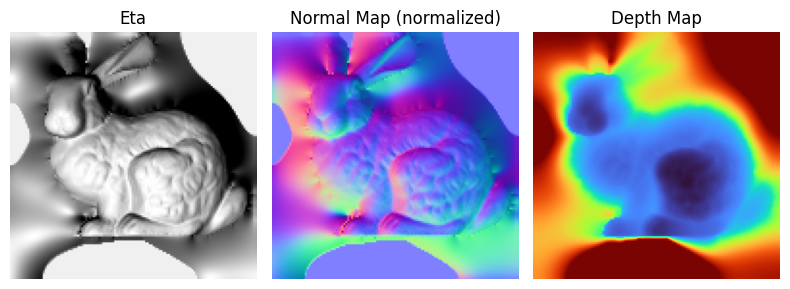

In [8]:
# Normal, p, q
normal_gt = compute_finite_difference_normals(verts_np, 128, 128, "fwd")
pq_gt = normal_gt / normal_gt[:, 2:3]
p_gt = pq_gt[:, 0]
q_gt = pq_gt[:, 1]
p_gt_2d = p_gt.reshape((height, width))
q_gt_2d = q_gt.reshape((height, width))
pq_gt_2d = pq_gt.reshape((height, width, 3))
pq_gt_2d_norm = pq_gt_2d / np.linalg.norm(pq_gt_2d, axis=-1, keepdims=True)

# Source direction
theta_s_gt = np.deg2rad(sim_params['theta_s'])
phi_s_gt   = np.deg2rad(sim_params['phi_s'])
sx_gt = math.sin(theta_s_gt) * math.cos(phi_s_gt)
sy_gt = math.sin(theta_s_gt) * math.sin(phi_s_gt)
sz_gt = math.cos(theta_s_gt)
ps_gt = sx_gt / sz_gt
qs_gt = sy_gt / sz_gt
s_vec_gt = np.array([ps_gt, qs_gt, 1.0])
print(f"ps_gt: {ps_gt}, qs_gt: {qs_gt}")

# Eta
eta_gt = compute_shading_value(p_gt, q_gt, ps_gt, qs_gt)
eta_gt_2d = eta_gt.reshape((height, width))

# Laplacian
lap_gt = cotan_laplacians_from_pq_np(pq_gt, width, height)
lap_gt_reshaped = lap_gt.reshape(126, 126, 6)

# depth
depth_values = verts_np[:, 2]
depth_map_gt = depth_values.reshape((height, width))

# Normal map
normal_map_norm = ((pq_gt_2d_norm + 1) / 2) * 255
normal_map_norm = normal_map_norm.astype(np.uint8)

fig, ax = plt.subplots(1, 3, figsize=(8, 6))
ax[0].imshow(eta_gt_2d, cmap='gray', origin='lower')
ax[0].set_title('Eta'), ax[0].axis('off')
ax[1].imshow(normal_map_norm, origin='lower')
ax[1].set_title('Normal Map (normalized)'), ax[1].axis('off')
ax[2].imshow(depth_map_gt, cmap='turbo', origin='lower')
ax[2].set_title('Depth Map'), ax[2].axis('off')

plt.tight_layout()
plt.show()

<!-- ### Get cotan $\tilde{\Delta}$ from GT normal (and compare to GT $\Delta$) -->

In [9]:
id_planar, L_planar = find_flat_regions(lap_gt)

<!-- ### Planar initialization -->

In [10]:
subset_init, scale = extract_candidates(id_planar, L_planar, eta_gt_2d, width, TOP_K=sim_params['candidates'])

<!-- ### Initial source direction estimation -->

In [11]:
pq_list = []
eta_list = []

N = len(subset_init)
for (pix_id, p, q, p, q, p, q, p, q, p, q, p, q) in subset_init:
    row_in = (pix_id // (width-2)) + 1
    col_in = (pix_id %  (width-2)) + 1
    
    eta_in = eta_gt_2d[row_in, col_in]
    pq_list.append([p, q])
    eta_list.append(eta_in)

pq_array = np.array(pq_list, dtype=np.float64)   # shape (N,2)
eta_array = np.array(eta_list, dtype=np.float64) # shape (N,)

In [12]:
def run_refinement(subset_init, lap_gt, width, height, ind_v, ind_a, ind_b, ind_d, ind_e, ind_f):
    
    results_refined = []

    for _, candidate in enumerate(subset_init):
        i, p_i, q_i, p_a, q_a, p_b, q_b, p_d, q_d, p_e, q_e, p_f, q_f = candidate

        row = (i // (width-2)) + 1
        col = (i %  (width-2)) + 1

        idx_i = np.ravel_multi_index((row, col), dims=(height, width))
        i_v = np.where(ind_v == idx_i)[0][0]
        idx_a = ind_a[i_v]
        idx_b = ind_b[i_v]
        idx_d = ind_d[i_v]
        idx_e = ind_e[i_v]
        idx_f = ind_f[i_v]
        
        x0 = np.array([p_i, q_i, p_a, q_a, p_b, q_b, 
                       p_d, q_d, p_e, q_e, p_f, q_f], dtype=np.float64)
        
        def wrapped_objective(x):
            return obj_function(x, idx_i, idx_a, idx_b, idx_d, idx_e, idx_f, i_v, lap_gt, width, height)
        
        res = minimize(wrapped_objective,
                       x0,
                       method="SLSQP",
                       options={"ftol": 1e-16})
        best_x = res.x

        # Results
        p_i, q_i, p_a, q_a, p_b, q_b, p_d, q_d, p_e, q_e, p_f, q_f = best_x
        results_refined.append((i, p_i, q_i, p_a, q_a, p_b, q_b, p_d, q_d, p_e, q_e, p_f, q_f))

    return results_refined

In [13]:
def compute_total_obj_function(subset_init, lap_gt, width, height, ind_v, ind_a, ind_b, ind_d, ind_e, ind_f):

    total_cost = 0.0
    for (pix_id, p_i, q_i, p_a, q_a, p_b, q_b, p_d, q_d, p_e, q_e, p_f, q_f) in subset_init:
        row_in = (pix_id // (width-2)) + 1
        col_in = (pix_id %  (width-2)) + 1

        idx_i = np.ravel_multi_index((row_in, col_in), dims=(height, width))
        i_v = np.where(ind_v == idx_i)[0][0]
        idx_a = ind_a[i_v]
        idx_b = ind_b[i_v]
        idx_d = ind_d[i_v]
        idx_e = ind_e[i_v]
        idx_f = ind_f[i_v]

        x = np.array([p_i, q_i, p_a, q_a, p_b, q_b, p_d, q_d, p_e, q_e, p_f, q_f], dtype=np.float64)

        pix_obj = obj_function(x, idx_i, idx_a, idx_b, idx_e, idx_d, idx_f, i_v, lap_gt, width, height)
        total_cost += pix_obj

    return total_cost

In [14]:
def ransac_estimate_ps_qs_with_sign(
    pq, eta,
    n_iter=8000,
    subset_size=8,
    inlier_thresh=0.05,
    min_inlier_ratio=0.3,
    random_state=0,
    refine=True
):
    pq = np.asarray(pq, float)
    eta = np.asarray(eta, float).reshape(-1)
    eta = np.clip(eta, -1.0, 1.0)

    # sanitize
    ok = np.isfinite(pq).all(axis=1) & np.isfinite(eta)
    pq = pq[ok]
    eta = eta[ok]
    N = pq.shape[0]
    if N < subset_size:
        raise ValueError(f"not enough points: {N} < subset_size={subset_size}")

    rng = np.random.default_rng(random_state)
    min_inliers = max(int(np.ceil(min_inlier_ratio * N)), subset_size)

    # shading function (your compute_shading_value if exists, otherwise fallback)
    shading_fn = globals().get("compute_shading_value", None)
    if shading_fn is None:
        def shading_fn(p, q, ps, qs):
            denom_n = np.sqrt(p*p + q*q + 1.0)
            denom_s = np.sqrt(ps*ps + qs*qs + 1.0)
            return (p*ps + q*qs + 1.0) / (denom_n * denom_s)

    best = None
    best_rmse = np.inf

    for _ in range(n_iter):
        idx = rng.choice(N, subset_size, replace=False)

        # Subset estimation
        try:
            ps0, qs0, _ = reverse_photometric_stereo(pq[idx], eta[idx])
        except Exception:
            continue
        if not (np.isfinite(ps0) and np.isfinite(qs0)):
            continue

        # Evaluate all points
        pred = shading_fn(pq[:, 0], pq[:, 1], ps0, qs0)
        err_pos = np.abs(pred - eta)
        err_neg = np.abs(-pred - eta)
        use_neg = err_neg < err_pos
        sign = np.where(use_neg, -1.0, +1.0)
        res = np.minimum(err_pos, err_neg)

        inliers = res < inlier_thresh
        if inliers.sum() < min_inliers:
            continue

        # Refine with all inliers
        if refine:
            eta_eff = sign[inliers] * eta[inliers]
            try:
                ps, qs, _ = reverse_photometric_stereo(pq[inliers], eta_eff)
            except Exception:
                continue
            if not (np.isfinite(ps) and np.isfinite(qs)):
                continue

            pred2 = shading_fn(pq[:, 0], pq[:, 1], ps, qs)
            err2_pos = np.abs(pred2 - eta)
            err2_neg = np.abs(-pred2 - eta)
            res2 = np.minimum(err2_pos, err2_neg)
            inliers2 = res2 < inlier_thresh
            if inliers2.sum() < min_inliers:
                continue

            rmse = float(np.sqrt(np.mean(res2[inliers2] ** 2)))
            if rmse < best_rmse:
                best_rmse = rmse
                best = (ps, qs, inliers2, (err2_neg < err2_pos))
        else:
            rmse = float(np.sqrt(np.mean(res[inliers] ** 2)))
            if rmse < best_rmse:
                best_rmse = rmse
                best = (ps0, qs0, inliers, use_neg)

    # Fallback to all data
    if best is None:
        ps, qs, residual = reverse_photometric_stereo(pq, eta)
        inliers = np.ones(N, dtype=bool)
        use_neg = np.zeros(N, dtype=bool)
        return ps, qs, best_rmse, inliers, use_neg, True

    ps, qs, inliers, use_neg = best
    return ps, qs, best_rmse, inliers, use_neg, False


def main_refinement(subset_init, width, height, lap_gt, eta_array, max_iter=None):

    ind_v, ind_a, ind_b, ind_c, ind_d, ind_e, ind_f, ind_g, ind_h = get_ngbr_indices(width, height)

    # ============== cost_prev =================
    cost_prev = compute_total_obj_function(subset_init, lap_gt, width, height, ind_v, ind_a, ind_b, ind_d, ind_e, ind_f)
    print(f"Initial cost = {cost_prev:.6f}")

    ps_final, qs_final, residual = np.nan, np.nan, np.inf


    # ==========================================================
    # Initial estimate (before refinement): ps, qs + angular error
    # ==========================================================
    ps_init, qs_init, residual_init, inliers_init, use_neg_init, fell_back_init = ransac_estimate_ps_qs_with_sign(
        pq_array, eta_array,
        n_iter=8000,
        subset_size=min(8, len(pq_array)),
        inlier_thresh=0.05,
        min_inlier_ratio=0.3,
        random_state=0,
        refine=True
    )

    print("Initial estimate (RANSAC)")
    print(f"    fell_back={fell_back_init}, inlier_ratio={float(inliers_init.mean()):.3f}, residual={residual_init:.6e}")
    print(f"    ps, qs = {ps_init:.3f}, {qs_init:.3f}")

    # Angular error for initial estimate
    s_gt = np.array([ps_gt, qs_gt, 1.0])
    s_init = np.array([ps_init, qs_init, 1.0])

    s_gt_norm = s_gt / np.linalg.norm(s_gt)
    s_init_norm = s_init / np.linalg.norm(s_init)

    dot_init = np.dot(s_gt_norm, s_init_norm)
    dot_init = np.clip(dot_init, -1.0, 1.0)

    angle_init_deg = np.degrees(np.arccos(dot_init))
    print(f"Angular error (initial): {angle_init_deg:.3f} degrees")

    for iter in range(1, max_iter + 1):
        # ======================= refine p,q ========================
        results_refined = run_refinement(subset_init, lap_gt, width, height, ind_v, ind_a, ind_b, ind_d, ind_e, ind_f)
        subset_init = results_refined

        # ==================== Estimate: ps,qs (RANSAC) ======================
        pq_list_refined = []
        for (pix_id, p_i, q_i, p_a, q_a, p_b, q_b, p_d, q_d, p_e, q_e, p_f, q_f) in subset_init:
            pq_list_refined.append([p_i, q_i])
        pq_array_refined = np.array(pq_list_refined, dtype=np.float64)

        eta_use = np.asarray(eta_array, dtype=np.float64).reshape(-1)

        ps_final, qs_final, residual, inliers, use_neg, fell_back = ransac_estimate_ps_qs_with_sign(
            pq_array_refined, eta_use,
            n_iter=8000,
            subset_size=min(8, len(pq_array_refined)),
            inlier_thresh=0.05,
            min_inlier_ratio=0.3,
            random_state=0,
            refine=True
        )

        print(f"    light(RANSAC): fell_back={fell_back}, inlier_ratio={float(inliers.mean()):.3f}, residual={residual:.6e}")

        # ============== cost_new =================
        cost_new = compute_total_obj_function(subset_init, lap_gt, width, height,
                                              ind_v, ind_a, ind_b, ind_d, ind_e, ind_f)
        print(f"Iter {iter:02d} | Cost new = {cost_new:.6f} | "
              f"inlier_ratio={float(np.mean(inliers)):.3f} | residual={residual:.6e}")

        diff_cost = abs(cost_new - cost_prev)
        cost_prev = cost_new
        if diff_cost < 1e-16:
            break

    return subset_init, ps_final, qs_final, residual

In [15]:
subset_refined, ps_final, qs_final, residual = main_refinement(subset_init, width, height, lap_gt,
                                                               eta_array, max_iter=10)
print("Refinement Done")
print(f"Ground truth  : ps, qs = {ps_gt:.3f}, {qs_gt:.3f}")
print(f"After  refined: ps, qs = {ps_final}, {qs_final}")
print(f"Residual: {residual:.6f}")

# Compute the angler error
s_gt = np.array([ps_gt, qs_gt, 1.0])
s_est = np.array([ps_final, qs_final, 1.0])

s_gt_norm = s_gt / np.linalg.norm(s_gt)
s_est_norm = s_est / np.linalg.norm(s_est)

dot_product = np.dot(s_gt_norm, s_est_norm)
dot_product = np.clip(dot_product, -1.0, 1.0)

angle_error_rad = np.arccos(dot_product)
angle_error_deg = np.degrees(angle_error_rad)

print(f"Angular error in light source direction: {angle_error_deg:.3f} degrees")

Initial cost = 18.226963


Initial estimate (RANSAC)
    fell_back=False, inlier_ratio=0.667, residual=1.317111e-02
    ps, qs = 0.348, -0.090
Angular error (initial): 17.923 degrees
    light(RANSAC): fell_back=False, inlier_ratio=0.600, residual=1.771698e-03
Iter 01 | Cost new = 0.233831 | inlier_ratio=0.600 | residual=1.771698e-03
    light(RANSAC): fell_back=False, inlier_ratio=0.600, residual=1.771698e-03
Iter 02 | Cost new = 0.233831 | inlier_ratio=0.600 | residual=1.771698e-03
Refinement Done
Ground truth  : ps, qs = 0.279, 0.234
After  refined: ps, qs = 0.25959296299888485, 0.24605189150109288
Residual: 0.001772
Angular error in light source direction: 1.219 degrees


In [16]:
def bfs_propagation(i_v_init, width, height):

    # Prepare
    N = (width - 2) * (height - 2)
    if not (0 <= i_v_init < N):
        return []
    visited = set()
    bfs_order_with_flag = []

    # (row, col) <-> local_id 
    def to_rc(local_id):
        r = local_id // (width - 2)
        c = local_id % (width - 2)
        return r, c

    def to_id(r, c):
        return r * (width - 2) + c

    # Functions
    # (1) Scan Right
    def scan_first_right(r0, c0):
        for c_ in range(c0, (width-2)):
            lid = to_id(r0, c_)
            if lid not in visited:
                visited.add(lid)
                bfs_order_with_flag.append((lid, "right"))

    # (2) Scan Right (down)
    def scan_diagonal_down_right(r0, c0):
        current_r, current_c = r0, c0
        while True:
            if not (0 <= current_r < (height - 2)):
                break
            if not (0 <= current_c < (width - 2)):
                break
            visited_any = False
            col_start = current_c
            first_in_this_row = True
            for c in range(col_start, (width - 2)):
                lid = to_id(current_r, c)
                if lid not in visited:
                    if first_in_this_row:
                        visited.add(lid)
                        bfs_order_with_flag.append((lid, "diagR_first"))
                        first_in_this_row = False
                    else:
                        visited.add(lid)
                        bfs_order_with_flag.append((lid, "right_diag"))
                    visited_any = True
            if not visited_any:
                break
            current_r += 1
            current_c += 1

    # (3) Scan Right (up)
    def scan_diagonal_down_right_left_side(r0, c0):
        current_r, current_c = r0, c0

        while True:
            if not (0 <= current_r < (height - 2)):
                break
            if not (0 <= current_c < (width - 2)):
                break

            visited_any = False
            first_in_this_row = True

            for col in range(current_c, (width - 2)):
                lid = to_id(current_r, col)
                if lid not in visited:
                    visited.add(lid)
                    if first_in_this_row:
                        bfs_order_with_flag.append((lid, "diagL_first"))
                        first_in_this_row = False
                    else:
                        bfs_order_with_flag.append((lid, "diagL_right"))
                    visited_any = True
            if not visited_any:
                break

            current_r -= 1
            current_c -= 1

    # (4) Scan Left up
    def scan_up_left_sequence(r0, c0):
        for row in range(r0 - 1, -1, -1):
            if row < 0:
                break
            visited_any = False
            first_in_line = True

            for col_ in reversed(range(0, c0 + 1)):
                lid = to_id(row, col_)
                if lid not in visited:
                    visited.add(lid)
                    if first_in_line:
                        bfs_order_with_flag.append((lid, "diagR_left"))
                        first_in_line = False
                    else:
                        bfs_order_with_flag.append((lid, "diagR_left"))
                    visited_any = True

            if not visited_any:
                break

    # (5) Scan Left down
    def scan_left(r0, c0):
        if c0 < 0:
            return
        start_col = c0 - 1 if (c0 - 1 >= 0) else c0

        current_r = r0
        current_c = start_col

        while True:
            if not (0 <= current_r < (height - 2)):
                break
            if not (0 <= current_c < (width - 2)):
                break

            visited_any = False
            first_in_line = True

            for col_ in range(current_c, -1, -1):
                lid = to_id(current_r, col_)
                if lid not in visited:
                    visited.add(lid)
                    if first_in_line:
                        bfs_order_with_flag.append((lid, "left"))
                        first_in_line = False
                    else:
                        bfs_order_with_flag.append((lid, "left"))
                    visited_any = True

            if not visited_any:
                break

            current_r += 1
            current_c += 1

            if not (0 <= current_r < (height - 2)):
                break
            if not (0 <= current_c < (width - 2)):
                break

    # (6) Scan Down
    def scan_right_to_left(r0, c0):
        current_r= r0
        current_c= c0
        while True:
            if not (0 <= current_r < (height-2)):
                break
            # clamp col
            if current_c>= (width-2):
                col_start= (width-2)-1
            else:
                col_start= current_c

            # scanning from col_start down to 0
            for col_ in range(col_start, -1, -1):
                if col_<0:
                    break
                lid= to_id(current_r,col_)
                if lid not in visited:
                    visited.add(lid)
                    bfs_order_with_flag.append((lid,"left"))

            current_r += 1

    # Main
    visited.add(i_v_init)
    bfs_order_with_flag.append((i_v_init, "init"))
    init_r, init_c = to_rc(i_v_init)
    
    # (1)
    scan_first_right(init_r, init_c + 1)
    # (2-1, 2-2)
    scan_diagonal_down_right(init_r + 1, init_c + 1)
    # (3-1, 3-2)
    if init_c - 1 >= 0:
       scan_diagonal_down_right_left_side(init_r -1, init_c)
    # (4)
    if init_r > 0 and init_c > 0:
        scan_up_left_sequence(init_r, init_c)
    # (5)
    scan_left(init_r, init_c)
    # (6)
    scan_right_to_left(0, (width-2)-1)
    
    return bfs_order_with_flag

[(15461, 'init'), (15462, 'right'), (15463, 'right'), (15464, 'right'), (15465, 'right'), (15466, 'right'), (15467, 'right'), (15468, 'right'), (15469, 'right'), (15470, 'right'), (15471, 'right'), (15472, 'right'), (15473, 'right'), (15474, 'right'), (15475, 'right'), (15476, 'right'), (15477, 'right'), (15478, 'right'), (15479, 'right'), (15480, 'right'), (15481, 'right'), (15482, 'right'), (15483, 'right'), (15484, 'right'), (15485, 'right'), (15486, 'right'), (15487, 'right'), (15488, 'right'), (15489, 'right'), (15490, 'right'), (15491, 'right'), (15492, 'right'), (15493, 'right'), (15494, 'right'), (15495, 'right'), (15496, 'right'), (15497, 'right'), (15588, 'diagR_first'), (15589, 'right_diag'), (15590, 'right_diag'), (15591, 'right_diag'), (15592, 'right_diag'), (15593, 'right_diag'), (15594, 'right_diag'), (15595, 'right_diag'), (15596, 'right_diag'), (15597, 'right_diag'), (15598, 'right_diag'), (15599, 'right_diag'), (15600, 'right_diag'), (15601, 'right_diag'), (15602, 'ri

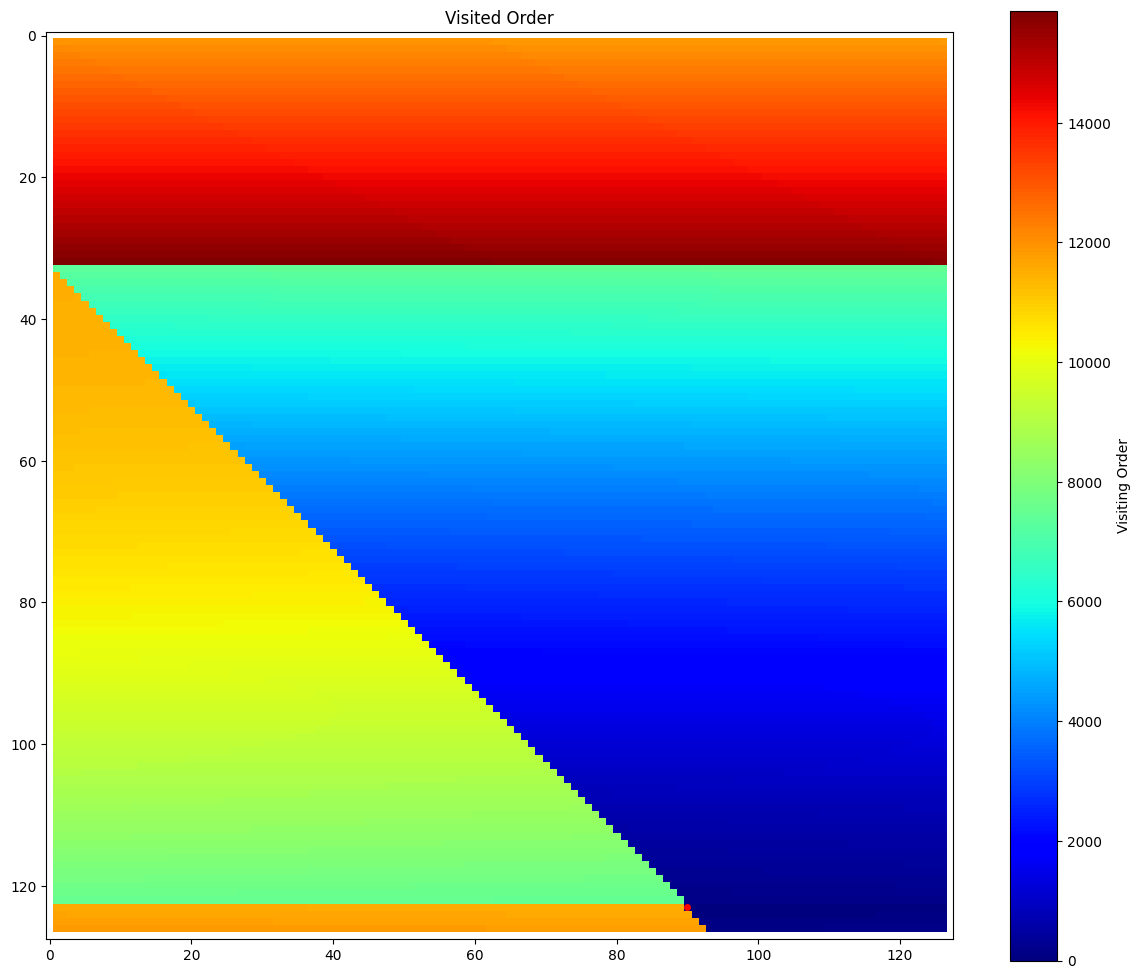

In [17]:
# Test visualization
i_v_init = subset_refined[0][0]
bfs_order = bfs_propagation(i_v_init, width, height)
print(bfs_order)

order_map = np.full((height, width), np.nan)
for idx, (pix_id, flag_str) in enumerate(bfs_order):
    row = pix_id // (width - 2) + 1
    col = pix_id %  (width - 2) + 1
    order_map[row, col] = idx

plt.figure(figsize=(12, 10))
plt.gca().set_facecolor("white")
plt.title("Visited Order")
plt.imshow(order_map, cmap="jet", vmin=0, vmax=len(bfs_order), alpha=1.0)
plt.colorbar(label="Visiting Order")

init_row = i_v_init // (width - 2) + 1
init_col = i_v_init %  (width - 2) + 1

plt.plot(init_col, init_row, "ro", markersize=4)
plt.tight_layout()
plt.show()

<!-- ### Objective Function  -->

In [18]:
# x,y,z (unit vector) -> p,q
def xyz_to_pq(x, y, z):
    if z == 0:
        raise ValueError("Input vector cannot be zero.")
    p = x / z
    q = y / z
    return p, q

In [24]:
def lap_error(x,
              idx_target, idx_a, idx_b, idx_d, idx_e, idx_f,
              i_v,
              gtlaplacian_default_np,
              width, height):
    
    p, q, p_a, q_a, p_b, q_b, p_f, q_f = x
    p_d = p + q_b - q
    p_e = p_f + q_a - q_f

    # Laplacian error
    pq_modified = np.zeros((height*width, 2), dtype=np.float64)
    pq_modified[idx_target, 0] = p
    pq_modified[idx_target, 1] = q
    pq_modified[idx_a, 1]      = q_a # a
    pq_modified[idx_b, 1]      = q_b # b
    pq_modified[idx_d, 0]      = p_d # d
    pq_modified[idx_e, 0]      = p_e # e
    pq_modified[idx_f, 0]      = p_f # f
    pq_modified[idx_f, 1]      = q_f # f
    
    lap_hat = cotan_laplacians_from_pq_np(pq_modified, width, height)
    diff_lap = gtlaplacian_default_np[i_v] - lap_hat[i_v]
    E_lap = np.mean(diff_lap**2)

    return E_lap

# def shading_error(x,
#                   idx_target, idx_a, idx_b, idx_f,
#                   eta_est_1d,
#                   ps_est, qs_est):

#     p, q, p_a, q_a, p_b, q_b, p_f, q_f = x

#     E_sha = 0.0

#     # Only 4 neighbors are enough
#     eta_center = eta_est_1d[idx_target]
#     shading_val = compute_shading_value(p, q, ps_est, qs_est)
#     E_sha += (shading_val - eta_center)**2

#     eta_a = eta_est_1d[idx_a]
#     shading_val = compute_shading_value(p_a, q_a, ps_est, qs_est)
#     E_sha += (shading_val - eta_a)**2

#     eta_b = eta_est_1d[idx_b]
#     shading_val = compute_shading_value(p_b, q_b, ps_est, qs_est)
#     E_sha += (shading_val - eta_b)**2

#     eta_f = eta_est_1d[idx_f]
#     shading_val = compute_shading_value(p_f, q_f, ps_est, qs_est)
#     E_sha += (shading_val - eta_f)**2    

#     return E_sha

def obj_function(x,
                 idx_target, idx_a, idx_b, idx_d, idx_e, idx_f,
                 i_v,
                 gtlaplacian_default_np,
                 width, height,
                 eta_est_1d,
                 ps_est, qs_est,
                 w_lap=None,
                 w_sha=None):
    
    E_lap = lap_error(x,
                      idx_target, idx_a, idx_b, idx_d, idx_e, idx_f,
                      i_v,
                      gtlaplacian_default_np,
                      width, height)

    # E_sha = shading_error(x,
    #                       idx_target, idx_a, idx_b, idx_f,
    #                       eta_est_1d,
    #                       ps_est, qs_est)

    return E_lap #w_sha * E_sha

In [25]:
def obj_function_t(x,
                   idx_target, idx_a, idx_b, idx_d, idx_e, idx_f,
                   i_v,
                   gtlaplacian_default_np,
                   width, height,
                   eta_est_1d,
                   final_est_source_vec,
                   w_lap=None):
    
    t, t_a, t_b, t_f = x

    # Eta
    eta_target = eta_est_1d[idx_target]
    eta_a = eta_est_1d[idx_a]
    eta_b = eta_est_1d[idx_b]
    eta_f = eta_est_1d[idx_f]

    # t -> p,q
    x, y, z = normal_components(t, eta_target, final_est_source_vec)
    xa, ya, za = normal_components(t_a, eta_a, final_est_source_vec)
    xb, yb, zb = normal_components(t_b, eta_b, final_est_source_vec)
    xf, yf, zf = normal_components(t_f, eta_f, final_est_source_vec)

    try:
        p  , q   = xyz_to_pq(x, y, z)
        p_a, q_a = xyz_to_pq(xa, ya, za)
        p_b, q_b = xyz_to_pq(xb, yb, zb)
        p_f, q_f = xyz_to_pq(xf, yf, zf)
    except ValueError:
        return np.inf

    p_d = p + q_b - q
    p_e = p_f + q_a - q_f

    # Laplacian error
    pq_modified = np.zeros((height*width, 2), dtype=np.float64)
    pq_modified[idx_target, 0] = p
    pq_modified[idx_target, 1] = q
    pq_modified[idx_a, 1]      = q_a # a
    pq_modified[idx_b, 1]      = q_b # b
    pq_modified[idx_d, 0]      = p_d # d
    pq_modified[idx_e, 0]      = p_e # e
    pq_modified[idx_f, 0]      = p_f # f
    pq_modified[idx_f, 1]      = q_f # f
    
    lap_hat = cotan_laplacians_from_pq_np(pq_modified, width, height)
    diff_lap = gtlaplacian_default_np[i_v] - lap_hat[i_v]
    E_lap = np.mean(diff_lap**2)

    return w_lap * E_lap

<!-- ### Run Propagation -->

In [26]:
def run_propagation(all_candidates_final,
                    gtlaplacian_default_np,
                    ind_v, ind_a, ind_b, ind_d, ind_e, ind_f,
                    width, height,
                    bfs_order_with_flag,
                    neighbor_dict,
                    eta_est_1d,
                    ps_est, qs_est,
                    refined_dict=None,
                    w_lap=None,
                    w_sha=None):

    # Preparation
    if refined_dict is None:
        refined_dict = {}
    N = (width - 2) * (height - 2)

    init_map = {}
    for candidate in all_candidates_final:
        local_id = candidate[0]
        init_map[local_id] = {"p":   candidate[1], "q":   candidate[2],
                              "p_a": candidate[3], "q_a": candidate[4],
                              "p_b": candidate[5], "q_b": candidate[6],
                              "p_f": candidate[7], "q_f": candidate[8]}

    # Optimization with bfs order
    bfs_index_map = {}
    for rank, (i_v, flag_str) in enumerate(bfs_order_with_flag):
        bfs_index_map[i_v] = rank

    def to_rc(local_id):
        r = local_id // (width - 2)
        c = local_id %  (width - 2)
        return r, c
    
    def to_id(r, c):
        return r * (width - 2) + c

    # =============================== Update functions ===============================
    # (1) Scan Right
    def update_with_left(current_id, idx_iter, current_vals):
        r, c = to_rc(current_id)
        if (c - 1) >= 0: # Left
            left_id = to_id(r, c-1)
            if left_id in refined_dict:
                left_val = refined_dict[left_id]
                current_vals["p_f"] = left_val["p_a"]
                current_vals["q_f"] = left_val["q_a"]
                current_vals["p"]   = left_val["p_b"]
                current_vals["q"]   = left_val["q_b"]
            else:
                current_vals["p_f"] = 0.0
                current_vals["q_f"] = 0.0
                current_vals["p"]   = 0.0
                current_vals["q"]   = 0.0

        return current_vals

    # (2-1) Diag-Right-Down (Refer to left-up)
    def update_with_diagL(current_id, idx_iter, current_vals):
        r, c = to_rc(current_id)
        
        if r > 0 and c > 0: # Diag-Left
            diagL_id = to_id(r-1, c-1)
            if diagL_id in refined_dict:
                diagL_val = refined_dict[diagL_id]
                current_vals["p_f"] = diagL_val["p"]
                current_vals["q_f"] = diagL_val["q"]
                #current_vals["p_a"] = diagL_val["p_b"]
                #current_vals["q_a"] = diagL_val["q_b"]
            else:
                current_vals["p_f"] = 0.0
                current_vals["q_f"] = 0.0
                #current_vals["p_a"] = 0.0
                #current_vals["q_a"] = 0.0
        else:
            current_vals["p_f"]   = 0.0
            current_vals["q_f"]   = 0.0
            #current_vals["p_a"] = 0.0
            #current_vals["q_a"] = 0.0

        if r > 0: # Up
            up_id = to_id(r-1, c)
            if up_id in refined_dict:
                up_val = refined_dict[up_id]
                current_vals["p_a"] = up_val["p"]
                current_vals["q_a"] = up_val["q"]
            else:
                current_vals["p_a"] = 0.0
                current_vals["q_a"] = 0.0
        else:
            current_vals["p_a"] = 0.0
            current_vals["q_a"] = 0.0

        return current_vals

    # (2-2) Scan Right (Refer to left-up)
    def update_with_diagL_right(current_id, idx_iter, current_vals):
        r, c = to_rc(current_id)

        if r > 0 and c > 0: # Diag-Left
            diag_left_id = to_id(r-1, c-1)
            if diag_left_id in refined_dict:
                diag_left_val = refined_dict[diag_left_id]
                current_vals["p_f"] = diag_left_val["p"]
                current_vals["q_f"] = diag_left_val["q"]
                #current_vals["p_a"] = diag_left_val["p_b"]
                #current_vals["q_a"] = diag_left_val["q_b"]
            else:
                current_vals["p_f"] = 0.0
                current_vals["q_f"] = 0.0
                #current_vals["p_a"] = 0.0
                #current_vals["q_a"] = 0.0
        else:
            current_vals["p_f"]   = 0.0
            current_vals["q_f"]   = 0.0
            #current_vals["p_a"] = 0.0
            #current_vals["q_a"] = 0.0

        if r > 0: # Up
            up_id = to_id(r-1, c)
            if up_id in refined_dict:
                up_val = refined_dict[up_id]
                current_vals["p_a"] = up_val["p"]
                current_vals["q_a"] = up_val["q"]
            else:
                current_vals["p_a"] = 0.0
                current_vals["q_a"] = 0.0
        else:
            current_vals["p_a"] = 0.0
            current_vals["q_a"] = 0.0

        # if c > 0: # Left
        #     left_id = to_id(r, c-1)
        #     if left_id in refined_dict:
        #         left_val = refined_dict[left_id]
        #         current_vals["p"] = left_val["p_b"]
        #         current_vals["q"] = left_val["q_b"]
        #     else:
        #         current_vals["p"] = 0.0
        #         current_vals["q"] = 0.0
        # else:
        #     current_vals["p"] = 0.0
        #     current_vals["q"] = 0.0

        return current_vals

    # (3-1) Scan Right (Refer to right-down)
    def update_with_diagR(current_id, idx_iter, current_vals):
        r, c = to_rc(current_id)

        # if (r+1) < (height - 2): # Down
        #     down_id = to_id(r+1, c)
        #     if down_id in refined_dict:
        #         down_val = refined_dict[down_id]
        #         current_vals["p"] = down_val["p_a"]
        #         current_vals["q"] = down_val["q_a"]
        #     else:
        #         current_vals["p"] = 0.0
        #         current_vals["q"] = 0.0
        # else:
        #     current_vals["p"] = 0.0
        #     current_vals["q"] = 0.0

        if (r + 1) < (height - 2) and (c + 1) < (width - 2): # Diag-Right
            diagR_id = to_id(r+1, c+1)
            if diagR_id in refined_dict:
                diagR_val = refined_dict[diagR_id]
                current_vals["p"]   = diagR_val["p_f"]
                current_vals["q"]   = diagR_val["q_f"]
                #current_vals["p_b"] = diagR_val["p_a"]
                #current_vals["q_b"] = diagR_val["q_a"]
            else:
                current_vals["p"]   = 0.0
                current_vals["q"]   = 0.0
                #current_vals["p_b"] = 0.0
                #current_vals["q_b"] = 0.0
        else:
            current_vals["p"]   = 0.0
            current_vals["q"]   = 0.0
            #current_vals["p_b"] = 0.0
            #current_vals["q_b"] = 0.0

        return current_vals

    # (3-2) Scan Right (Refer to right-down and Left)
    def update_with_diagR_left(current_id, idx_iter, current_vals):
        r, c = to_rc(current_id)

        # if (r+1) < (height - 2): # Down
        #     down_id = to_id(r+1, c)
        #     if down_id in refined_dict:
        #         down_val = refined_dict[down_id]
        #         current_vals["p"] = down_val["p_a"]
        #         current_vals["q"] = down_val["q_a"]
        #     else:
        #         current_vals["p"] = 0.0
        #         current_vals["q"] = 0.0
        # else:
        #     current_vals["p"] = 0.0
        #     current_vals["q"] = 0.0

        if (r + 1) < (height - 2) and (c + 1) < (width - 2): # Diag-Right
            diagR_id = to_id(r+1, c+1)
            if diagR_id in refined_dict:
                diagR_val = refined_dict[diagR_id]
                current_vals["p"]   = diagR_val["p_f"]
                current_vals["q"]   = diagR_val["q_f"]
                # current_vals["p_b"] = diagR_val["p_a"]
                # current_vals["q_b"] = diagR_val["q_a"]
            else:
                current_vals["p"]   = 0.0
                current_vals["q"]   = 0.0
                # current_vals["p_b"] = 0.0
                # current_vals["q_b"] = 0.0
        else:
            current_vals["p"]   = 0.0
            current_vals["q"]   = 0.0
            # current_vals["p_b"] = 0.0
            # current_vals["q_b"] = 0.0

        # if (c - 1) >= 0: # Left
        #     left_id = to_id(r, c-1)
        #     if left_id in refined_dict:
        #         left_val = refined_dict[left_id]
        #         #current_vals["p"]   = left_val["p_b"]
        #         #current_vals["q"]   = left_val["q_b"]                
        #         current_vals["p_f"] = left_val["p_a"]
        #         current_vals["q_f"] = left_val["q_a"]
        #     else:
        #         #current_vals["p"]   = 0.0
        #         #current_vals["q"]   = 0.0
        #         current_vals["p_f"] = 0.0
        #         current_vals["q_f"] = 0.0
        # else:
        #     #current_vals["p"]   = 0.0
        #     #current_vals["q"]   = 0.0
        #     current_vals["p_f"] = 0.0
        #     current_vals["q_f"] = 0.0

        return current_vals

    # (4-1) Scan Left (Refer to Right)
    def update_with_diagR_right(current_id, idx_iter, current_vals):
        r, c = to_rc(current_id)

        if (r + 1) < (height - 2) and (c + 1) < (width - 2): # Diag-Right
            diagR_id = to_id(r+1, c+1) 
            if diagR_id in refined_dict:
                diagR_val = refined_dict[diagR_id]
                #current_vals["p"] = diagR_val["p_f"]
                #current_vals["q"] = diagR_val["q_f"]
                current_vals["p_b"] = diagR_val["p_a"]
                current_vals["q_b"] = diagR_val["q_a"]
            else:
                #current_vals["p"]   = 0.0
                #current_vals["q"]   = 0.0
                current_vals["p_b"] = 0.0
                current_vals["q_b"] = 0.0
        else:
            #current_vals["p"]   = 0.0
            #current_vals["q"]   = 0.0
            current_vals["p_b"] = 0.0
            current_vals["q_b"] = 0.0

        if (c + 1) < (width - 2): # Right
            right_id = to_id(r, c+1)
            if right_id in refined_dict:
                right_val = refined_dict[right_id]
                current_vals["p_a"] = right_val["p_f"]
                current_vals["q_a"] = right_val["q_f"]
                #current_vals["p_b"] = right_val["p"]
                #current_vals["q_b"] = right_val["q"]
            else:
                current_vals["p_a"] = 0.0
                current_vals["q_a"] = 0.0
                #current_vals["p_b"] = 0.0
                #current_vals["q_b"] = 0.0
        else:
            current_vals["p_a"] = 0.0
            current_vals["q_a"] = 0.0
            #current_vals["p_b"] = 0.0
            #current_vals["q_b"] = 0.0

        # if r > 0: # Up
        #     up_id = to_id(r-1, c)
        #     if up_id in refined_dict:
        #         up_val = refined_dict[up_id]
        #         current_vals["p_a"] = up_val["p"]
        #         current_vals["q_a"] = up_val["q"]
        #     else:
        #         current_vals["p_a"] = 0.0
        #         current_vals["q_a"] = 0.0
        # else:
        #     current_vals["p_a"] = 0.0
        #     current_vals["q_a"] = 0.0

        return current_vals

    # (5) Scan Left Down
    def update_with_right(current_id, idx_iter, current_vals):
        r, c = to_rc(current_id)

        if (c + 1) < (width - 2): # Right
            right_id = to_id(r, c+1)
            if right_id in refined_dict:
                right_val = refined_dict[right_id]
                #current_vals["p_a"] = right_val["p_f"]
                #current_vals["q_a"] = right_val["q_f"]
                current_vals["p_b"] = right_val["p"]
                current_vals["q_b"] = right_val["q"]
            else:
                #current_vals["p_a"] = 0.0
                #current_vals["q_a"] = 0.0
                current_vals["p_b"] = 0.0
                current_vals["q_b"] = 0.0
        else:
            #current_vals["p_a"] = 0.0
            #current_vals["q_a"] = 0.0
            current_vals["p_b"] = 0.0
            current_vals["q_b"] = 0.0

        # if r > 0: # Up
        #     up_id = to_id(r-1, c)
        #     if up_id in refined_dict:
        #         up_val = refined_dict[up_id]
        #         current_vals["p_a"] = up_val["p"]
        #         current_vals["q_a"] = up_val["q"]
        #     else:
        #         current_vals["p_a"] = 0.0
        #         current_vals["q_a"] = 0.0
        # else:
        #     current_vals["p_a"] = 0.0
        #     current_vals["q_a"] = 0.0

        if r > 0 and c > 0: # Diag-Left
            diagL_id = to_id(r-1, c-1)
            if diagL_id in refined_dict:
                diagL_val = refined_dict[diagL_id]
                current_vals["p_a"] = diagL_val["p_b"]
                current_vals["q_a"] = diagL_val["q_b"]
                current_vals["p_f"] = diagL_val["p"]
                current_vals["q_f"] = diagL_val["q"]
            else:
                current_vals["p_a"] = 0.0
                current_vals["q_a"] = 0.0
                current_vals["p_f"] = 0.0
                current_vals["q_f"] = 0.0
        else:
            current_vals["p_a"] = 0.0
            current_vals["q_a"] = 0.0
            current_vals["p_f"] = 0.0
            current_vals["q_f"] = 0.0

        return current_vals

    # ===========================================================================
    def decide_optim_mode(direction):
        if direction == "init":
            return {"p":   "free",  "q":   "free",
                    "p_a": "free",  "q_a": "free",
                    "p_b": "free",  "q_b": "free",
                    "p_f": "free",  "q_f": "free"}
        # (1)
        elif direction == "right":
            return {"p":   "free",  "q":   "free",
                    "p_a": "free",  "q_a": "free",
                    "p_b": "free",  "q_b": "free",
                    "p_f": "free",  "q_f": "free"}

        # (2-1)
        elif direction == "diagR_first":
            return {"p":   "free",  "q":   "free",
                    "p_a": "fix",   "q_a": "fix",
                    "p_b": "free",  "q_b": "free",
                    "p_f": "fix",   "q_f": "fix"}
        # (2-2)
        elif direction == "right_diag":
            return {"p":   "free",  "q":   "free",
                    "p_a": "fix",   "q_a": "fix",
                    "p_b": "free",  "q_b": "free",
                    "p_f": "fix",   "q_f": "fix"}      
        # (3-1)
        elif direction == "diagL_first":
            return {"p":   "fix",   "q":   "fix",
                    "p_a": "free",  "q_a": "free",
                    "p_b": "free",  "q_b": "free",
                    "p_f": "free",  "q_f": "free"}

        # (3-2)
        elif direction == "diagL_right":
            return {"p":   "fix",   "q":   "fix",
                    "p_a": "free",  "q_a": "free",
                    "p_b": "free",  "q_b": "free",
                    "p_f": "free",  "q_f": "free"}

        # (4)
        elif direction == "diagR_left":
            return {"p":   "free",  "q":   "free",
                    "p_a": "fix",   "q_a": "fix",
                    "p_b": "fix",   "q_b": "fix",
                    "p_f": "free",  "q_f": "free"}
        
        # (5)
        elif direction == "left":
            return {"p":   "free",  "q":   "free",
                    "p_a": "fix",   "q_a": "fix",
                    "p_b": "fix",   "q_b": "fix",
                    "p_f": "fix",   "q_f": "fix"}
        else:
            return {"p":   "free","q":   "free",
                    "p_a": "free","q_a": "free",
                    "p_b": "free","q_b": "free",
                    "p_f": "free","q_f": "free"}

    def build_x_init_and_bounds(current_vals, mode_dict):
        DELTA = 0.6
        param_keys = ["p","q","p_a","q_a","p_b","q_b","p_f","q_f"]
        x_init = []
        param_bounds = []

        for k in param_keys:
            val = current_vals[k]
            if abs(val) < 1e-15:
                mode = "free"
            else:
                mode = mode_dict[k]
            if mode == "fix":
                lower, upper = val, val
            elif mode == "semi":
                lower, upper = (val - DELTA), (val + DELTA)
            else:  #  "free"
                lower, upper = None, None
            x_init.append(val)
            param_bounds.append((lower, upper))
        return x_init, param_bounds, param_keys


    # ================================ Main ================================
    for idx_iter, (pix_id, flag_str) in enumerate(tqdm(bfs_order_with_flag)):
        # (A) First pixel
        if pix_id not in refined_dict:
            refined_dict[pix_id] = init_map.get(pix_id, {"p":0.0,"q":0.0,"p_a":0.0,"q_a":0.0,
                                                             "p_b":0.0,"q_b":0.0,"p_f":0.0,"q_f":0.0})

        # (B) Scond or later pixel
        if pix_id in refined_dict:
            current_vals = refined_dict[pix_id].copy()
        else:
            # neighbor_ids etc
            neighbor_ids = []
            for (nb_idx, _) in neighbor_dict[pix_id]:
                if 0 <= nb_idx < N and (nb_idx in refined_dict):
                    neighbor_ids.append(nb_idx)
            if neighbor_ids:
                best_nb_id = min(neighbor_ids, key=lambda x: bfs_index_map[x])
                current_vals = refined_dict[best_nb_id].copy()
            else:
                current_vals = init_map.get(pix_id, {"p":0.0,"q":0.0,"p_a":0.0,"q_a":0.0,
                                                     "p_b":0.0,"q_b":0.0,"p_f":0.0,"q_f":0.0})

        # ================================ Reference ================================
        # (0)
        if flag_str == "init":
            direction = "init"
        # (1)
        elif flag_str == "right":
            current_vals = update_with_left(pix_id, idx_iter, current_vals)
            direction = "right"
        # (2-1)
        elif flag_str == "diagR_first":
            current_vals = update_with_diagL(pix_id, idx_iter, current_vals)
            direction = "diagR_first"
        # (2-2)
        elif flag_str == "right_diag":
            current_vals = update_with_diagL_right(pix_id, idx_iter, current_vals)
            direction = "right_diag"
        # (3-1)
        elif flag_str == "diagL_first":
            current_vals = update_with_diagR(pix_id, idx_iter, current_vals)
            direction = "diagL_first"
        # (3-2)
        elif flag_str == "diagL_right":
            current_vals = update_with_diagR_left(pix_id, idx_iter, current_vals)
            direction = "diagL_right"
        # (4)
        elif flag_str == "diagR_left":
            current_vals = update_with_diagR_right(pix_id, idx_iter, current_vals)
            direction = "diagR_left"
        # (5)
        elif flag_str == "left":
            current_vals = update_with_right(pix_id, idx_iter, current_vals)
            direction = "left"
        else:
            direction = "other"

        mode_dict = decide_optim_mode(direction)
        x_init, param_bounds, param_keys = build_x_init_and_bounds(current_vals, mode_dict)

        idx_target = ind_v[pix_id]
        idx_a = ind_a[pix_id]
        idx_b = ind_b[pix_id]
        idx_d = ind_d[pix_id]
        idx_e = ind_e[pix_id]
        idx_f_ = ind_f[pix_id]

        def local_objective_function(x_opt):
            return obj_function(x_opt,
                                idx_target, idx_a, idx_b, idx_d, idx_e, idx_f_,
                                pix_id,
                                gtlaplacian_default_np,
                                width, height,
                                eta_est_1d,
                                ps_est, qs_est,
                                w_lap=w_lap, w_sha=w_sha)
        if len(x_init) > 0:
            res = minimize(
                local_objective_function,
                x_init,
                method="L-BFGS-B",
                #bounds=param_bounds,
                options={"ftol": 1e-12,
                         "maxiter": 10000,
                         "maxfun": 10000,
                         "disp": False} 
            )
            x_result = res.x
            cost_1 = res.fun
        else:
            x_result = x_init
            cost_1 = local_objective_function(x_init)

        updated_vals = {}
        for i2, key in enumerate(param_keys):
            updated_vals[key] = x_result[i2]

        # ========== save refined_dict ==========
        refined_dict[pix_id] = updated_vals

    # ============= Get result =============
    result_list=[]
    for local_id, vals in refined_dict.items():
        result_list.append((local_id,
                            vals["p"],   vals["q"],
                            vals["p_a"], vals["q_a"],
                            vals["p_b"], vals["q_b"],
                            vals["p_f"], vals["q_f"]))
    return result_list, refined_dict

In [28]:
ind_v, ind_a, ind_b, ind_c, ind_d, ind_e, ind_f, ind_g, ind_h = get_ngbr_indices(width, height)

neighbor_dict = prepare_neighbor_dict(ind_v, ind_a, ind_b, ind_c, ind_d, ind_e, ind_f, width, height)
i_v_init = subset_refined[0][0]
bfs_order_with_flag = bfs_propagation(i_v_init, width, height)
final_est_source_vec = np.array([ps_final, qs_final, 1.0], dtype=np.float64)
final_est_source_vec /= np.linalg.norm(final_est_source_vec)  # Normalize

result_list, refined_dict = run_propagation(
    subset_refined,
    lap_gt,
    ind_v, ind_a, ind_b, ind_d, ind_e, ind_f,
    width, height,
    bfs_order_with_flag=bfs_order_with_flag,
    neighbor_dict=neighbor_dict,
    eta_est_1d=eta_gt,
    ps_est=s_est_norm[0],
    qs_est=s_est_norm[1],
    refined_dict=None,
    w_lap=1000.0,
    w_sha=1.0,
)

  0%|          | 0/15876 [00:00<?, ?it/s]

100%|██████████| 15876/15876 [40:05<00:00,  6.60it/s]  


(-0.5, 125.5, -0.5, 125.5)

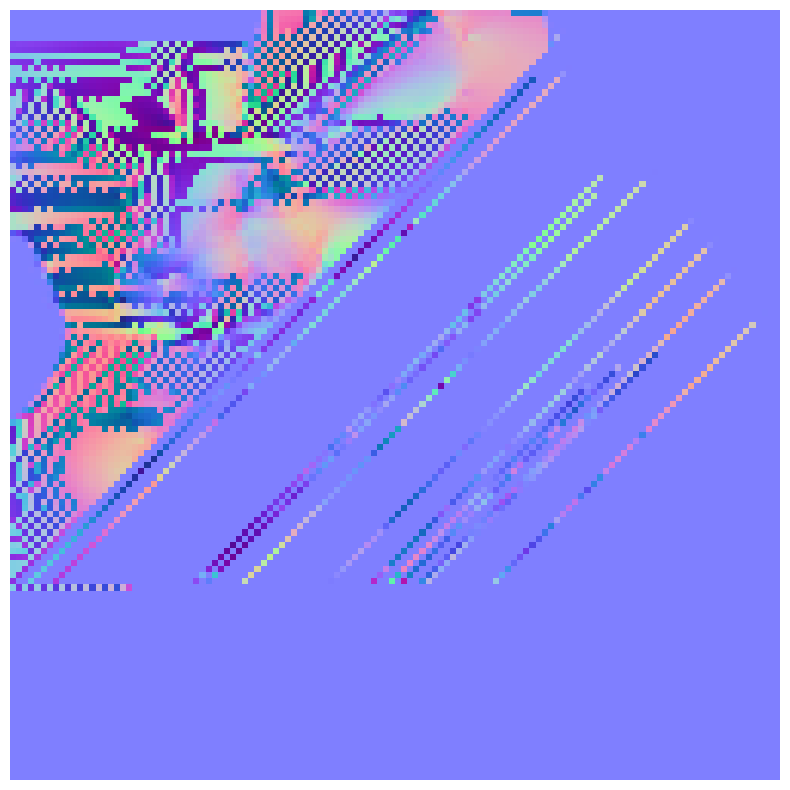

In [29]:
# Visualize normal map
h_in, w_in = height - 2, width - 2
normal_map = np.zeros((h_in, w_in, 3), dtype=np.float32)
p_map = np.zeros((h_in, w_in), dtype=np.float32)
q_map = np.zeros((h_in, w_in), dtype=np.float32)

for (i_v, p, q, p_a, q_a, p_b, q_b, p_f, q_f) in result_list:
    row = i_v // w_in
    col = i_v % w_in
    p_map[row, col] = p
    q_map[row, col] = q
    
    nx = p
    ny = q
    nz = 1.0

    length = np.sqrt(nx*nx + ny*ny + nz*nz)
    nx /= length
    ny /= length
    nz /= length

    normal_map[row, col, 0] = nx
    normal_map[row, col, 1] = ny
    normal_map[row, col, 2] = nz

normal_img = 0.5 * (normal_map + 1.0)
normal_img = np.clip(normal_img, 0.0, 1.0)

plt.figure(figsize=(10,10))
plt.imshow(normal_img, origin="lower")
plt.axis("off")
# plt.savefig(f"estimated_normal_{params.obj_name}_SFS.png", dpi=300, bbox_inches='tight')
#plt.title("Normal Map - Propagation")
#plt.show()

# init_row = i_v_init // (width - 2) + 1
# init_col = i_v_init %  (width - 2) + 1
# plt.plot(init_col, init_row, "ro", markersize=4)
# plt.tight_layout()
# plt.show()

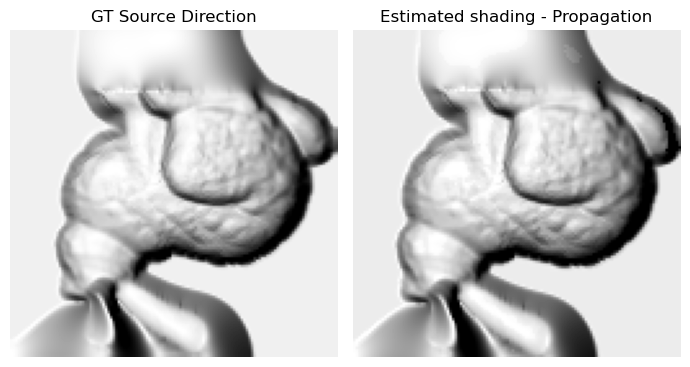

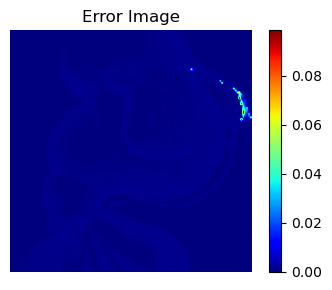

In [ ]:
# p_flat = p_map.flatten()
# q_flat = q_map.flatten()
# eta_est_1d = compute_shading_value(p_flat, q_flat, ps_final, ps_final)
# eta_est_2d = eta_est_1d.reshape((h_in, w_in))
# eta_gt_in = eta_gt[1:-1, 1:-1]
# error_image_final = (eta_gt_in - eta_est_2d)**2

# plt.figure(figsize=(7,5))
# plt.subplot(1,2,1)
# plt.title("GT Source Direction")
# plt.imshow(eta_gt, cmap='gray')
# plt.axis("off")
# plt.subplot(1,2,2)
# plt.title("Estimated shading - Propagation")
# plt.imshow(eta_est_2d, cmap='gray')
# plt.axis("off")
# plt.tight_layout()
# plt.show()

# plt.figure(figsize=(4,3))
# plt.title("Error Image")
# plt.imshow(error_image_final, cmap='jet')
# plt.axis("off")
# plt.colorbar()
# plt.tight_layout()
# plt.show()

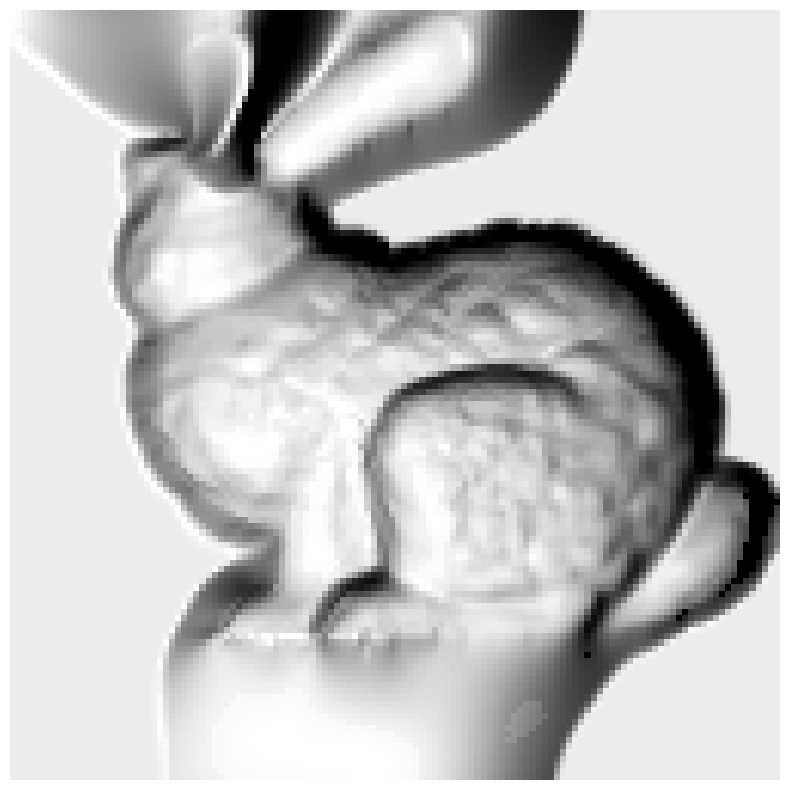

In [ ]:
# plt.figure(figsize=(10,10))
# plt.imshow(eta_est_2d, cmap='gray', origin="lower")
# plt.axis("off")
# plt.savefig(f"estimated_shading_{params.obj_name}_SFS.png", dpi=300, bbox_inches='tight')
# plt.show()

Mean angle error (degrees): 26.59807032066086
Median angle error (degrees): 15.216681746290487
Mean ± STD (degrees): 26.60 ± 30.25


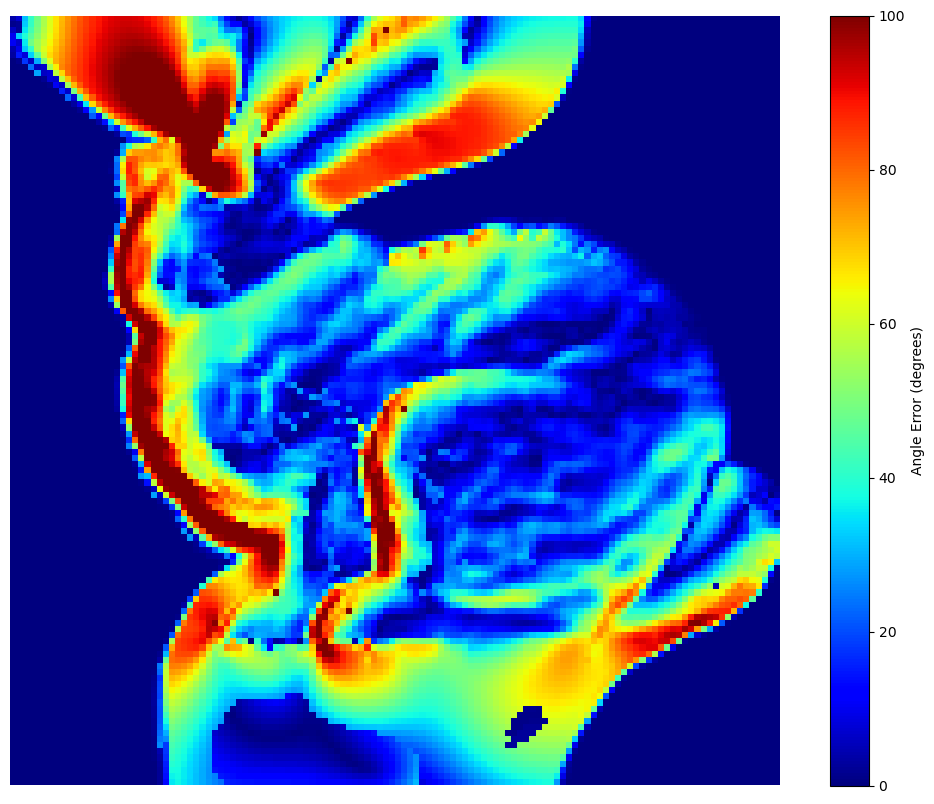

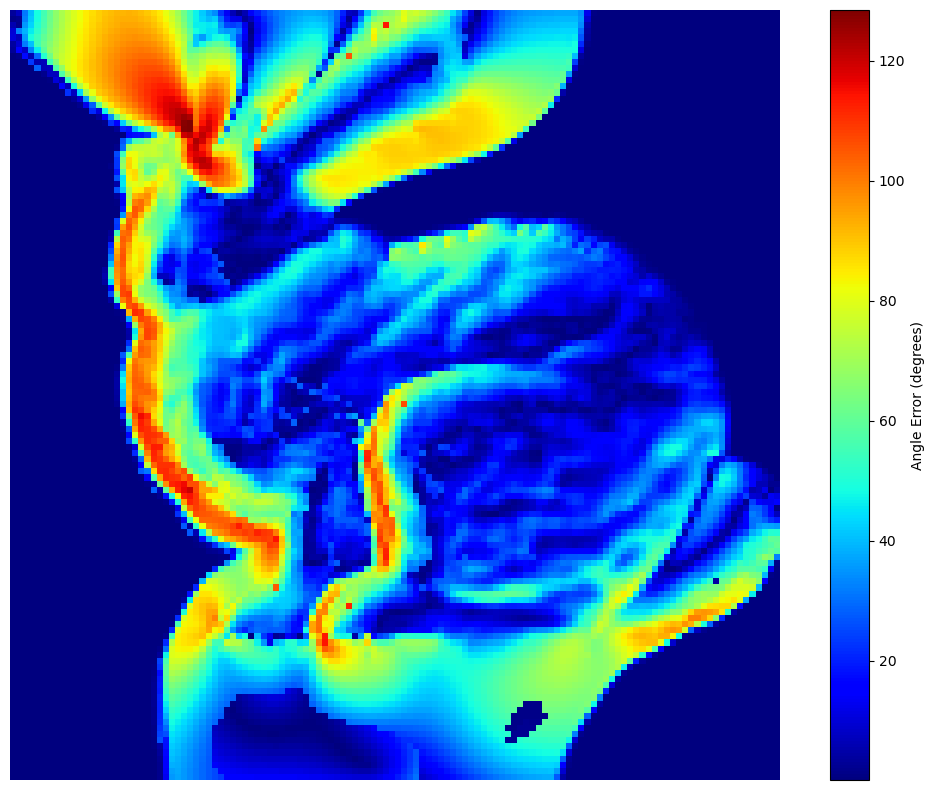

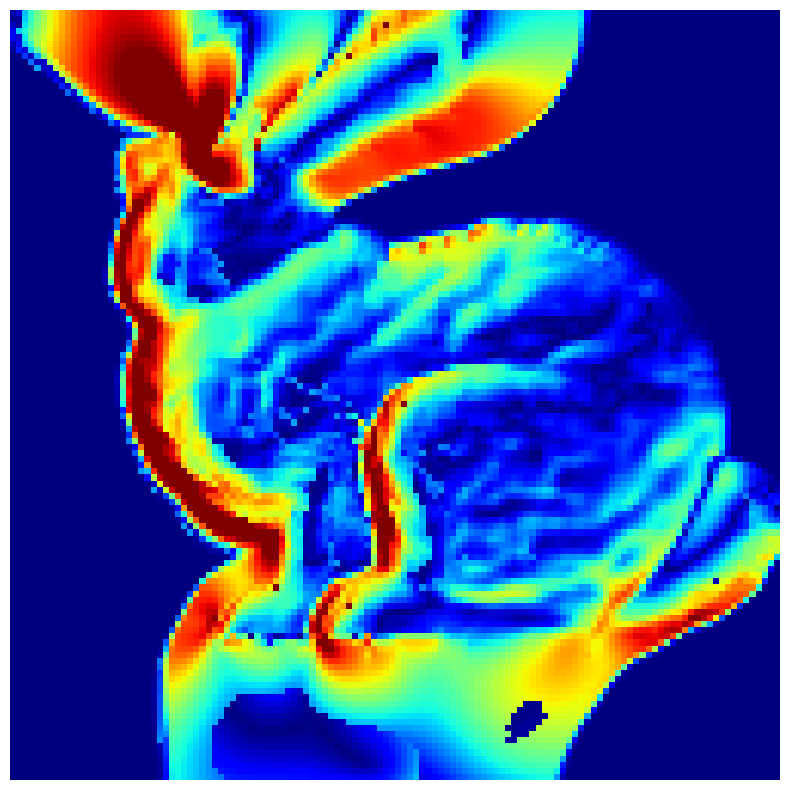

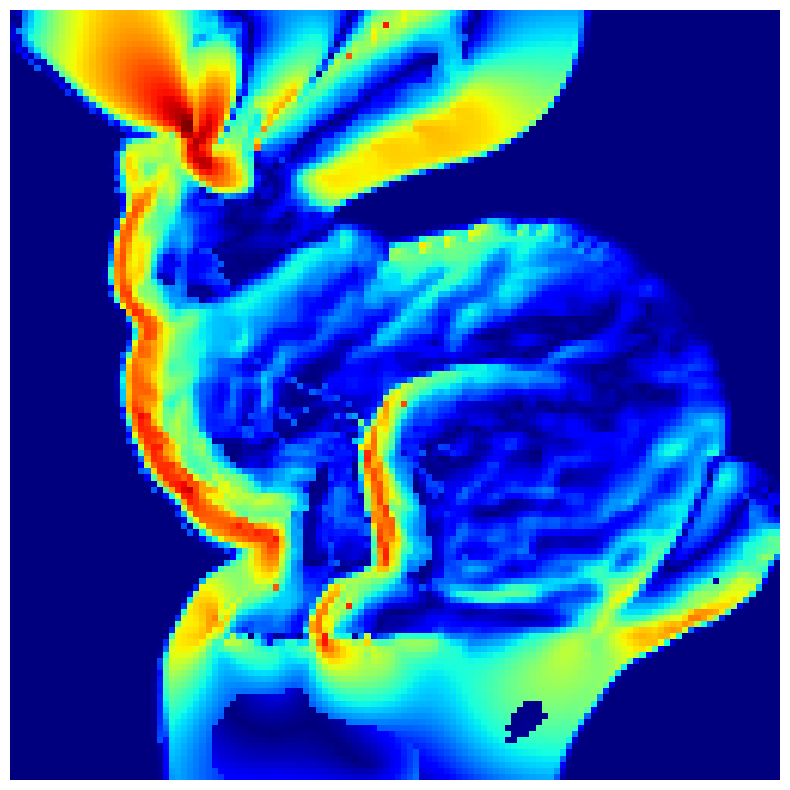

In [ ]:
# gt_normal_map_full = gtnormals_pq_np.reshape((height, width, 3))
# gt_normal_map = gt_normal_map_full[1:-1, 1:-1, :]  # shape: (height-2, width-2, 3)

# # --- Normalize Ground Truth Normals ---
# norm_est = np.linalg.norm(normal_map, axis=-1, keepdims=True)
# norm_gt  = np.linalg.norm(gt_normal_map, axis=-1, keepdims=True)
# estimated_normals = normal_map / np.maximum(norm_est, 1e-8)
# ground_truth_normals = gt_normal_map / np.maximum(norm_gt, 1e-8)

# # --- Angle Error Calculation ---
# dot_product = np.sum(estimated_normals * ground_truth_normals, axis=-1)
# dot_product = np.clip(dot_product, -1.0, 1.0)

# angle_error_rad = np.arccos(dot_product)     # [rad]
# angle_error_deg = np.degrees(angle_error_rad)  # [°]

# # Mean angle error
# mean_error = np.mean(angle_error_deg)
# print("Mean angle error (degrees):", mean_error)

# # Median angle error
# median_error = np.median(angle_error_deg)
# print("Median angle error (degrees):", median_error)

# std_error = np.std(angle_error_deg)
# print("Mean ± STD (degrees): {:.2f} ± {:.2f}".format(mean_error, std_error))


# plt.figure(figsize=(13,10))
# plt.imshow(angle_error_deg, cmap='jet', origin='lower', vmin=0, vmax=100)
# plt.colorbar(label='Angle Error (degrees)')
# plt.axis("off")
# plt.savefig(f"angle_error_map_with_colorbar_scaled_{params.obj_name}_SFS.png", dpi=300, bbox_inches='tight')
# plt.show()

# plt.figure(figsize=(13,10))
# plt.imshow(angle_error_deg, cmap='jet', origin='lower')
# plt.colorbar(label='Angle Error (degrees)')
# plt.axis("off")
# plt.savefig(f"angle_error_map_with_colorbar_{params.obj_name}_SFS.png", dpi=300, bbox_inches='tight')
# plt.show()

# plt.figure(figsize=(13,10))
# plt.imshow(angle_error_deg, cmap='jet', origin='lower', vmin=0, vmax=100)
# plt.axis("off")
# plt.savefig(f"angle_error_map_without_colorbar_scaled_{params.obj_name}_SFS.png", dpi=300, bbox_inches='tight')
# plt.show()

# plt.figure(figsize=(13,10))
# plt.imshow(angle_error_deg, cmap='jet', origin='lower')
# plt.axis("off")
# plt.savefig(f"angle_error_map_without_colorbar_{params.obj_name}_SFS.png", dpi=300, bbox_inches='tight')
# plt.show()


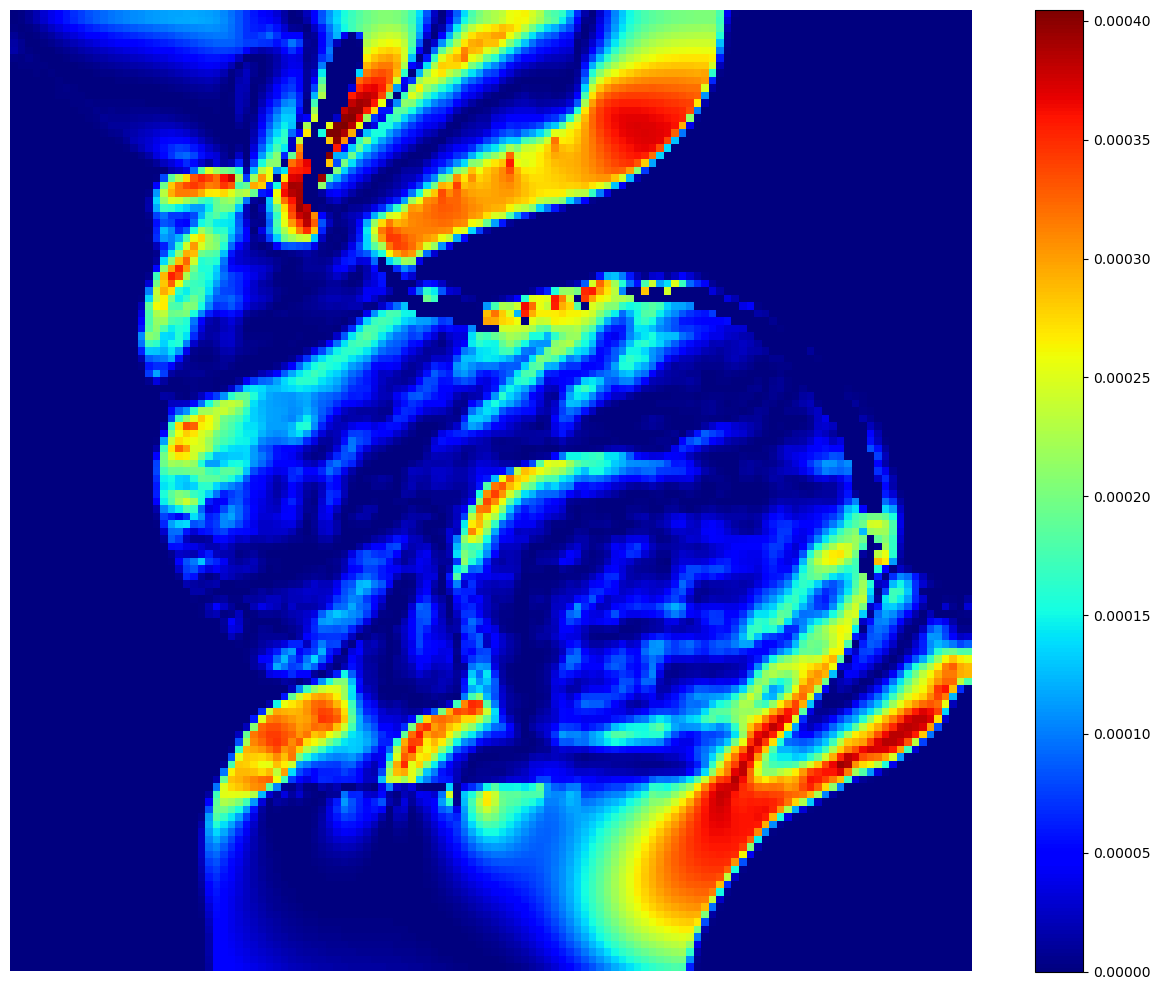

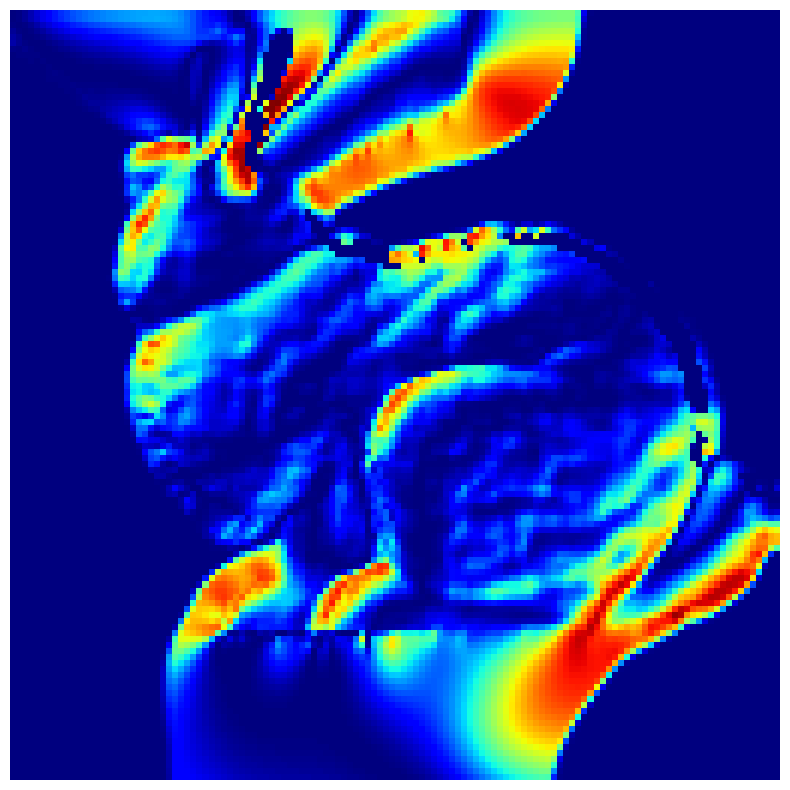

In [ ]:
# # Shading image
# eta_est_1d_est = compute_shading_value(p_gt, q_gt, ps_est, qs_est)
# eta_est = eta_est_1d_est.reshape((height, width))
# error_image = (eta_gt - eta_est)**2

# plt.figure(figsize=(13,10))
# plt.imshow(error_image, cmap='jet', origin='lower')
# plt.axis("off")
# plt.colorbar()
# plt.savefig(f"source_direction_error_map_with_colorbar_{params.obj_name}_SFS.png", dpi=300, bbox_inches='tight')
# plt.tight_layout()
# plt.show()

# plt.figure(figsize=(13,10))
# plt.imshow(error_image, cmap='jet', origin='lower')
# plt.axis("off")
# plt.savefig(f"source_direction_error_map_colorbar_{params.obj_name}_SFS.png", dpi=300, bbox_inches='tight')
# plt.show()


In [ ]:
# # Calculate the differences
# ps_diff = abs(ps_gt - ps_final)
# qs_diff = abs(qs_gt - qs_final)

# # Print the results
# print(f"Difference in ps: {ps_diff}")
# print(f"Difference in qs: {qs_diff}")
# print(f"GT ps: {ps_gt}, GT qs: {qs_gt}")
# print(f"Final ps: {ps_final}, Final qs: {qs_final}")
# print(f"Estimated ps (before refined): {ps_est}, Estimated qs (before refined): {qs_est}")

Difference in ps: 0.015125928373165842
Difference in qs: 0.015301223209076453
GT ps: 0.2788173754203369, GT qs: 0.23395555688102193
Final ps: 0.29394330379350275, Final qs: 0.21865433367194548
Estimated ps (before refined): 0.2939427785128968, Estimated qs (before refined): 0.218653861942354


In [ ]:
# v_gt = np.array([ps_gt, qs_gt, 1.0])
# v_final = np.array([ps_final, qs_final, 1.0])

# v_gt_norm = v_gt / np.linalg.norm(v_gt)
# v_final_norm = v_final / np.linalg.norm(v_final)

# dot_product = np.dot(v_gt_norm, v_final_norm)
# dot_product = np.clip(dot_product, -1.0, 1.0)

# angle_error_rad = np.arccos(dot_product)
# angle_error_deg = np.degrees(angle_error_rad)

# print(f"Angular error in light source direction: {angle_error_deg} degrees")

Angular error in light source direction: 1.1571509988890762 degrees


In [ ]:
# np.savez(f"results_{params.obj_name}_SFS.npz",
#          result_list=np.array(result_list, dtype=object),
#          refined_dict=refined_dict,
#          source_vec=final_est_source_vec,
#          ps_gt=ps_gt,
#          qs_gt=qs_gt,
#          ps_est=ps_est,
#          qs_est=qs_est,
#          ps_final=ps_final,
#          qs_final=qs_final,
#          eta_est_2d=eta_est_2d,
#          eta_gt=eta_gt,
#          mean_error=mean_error,
#          median_error=median_error,
#          estimated_normals=estimated_normals,
#          all_candidates=np.array(all_candidates, dtype=object),
#          all_candidates_final=np.array(all_candidates_final, dtype=object))

In [ ]:
# 

In [ ]:
# 